# Phase 4b — 공유된 1D 오토인코더는 왜 잘 되나? (한 요소씩 바꿔보기)

Dacon에 공유된 "매우 간단한 1D AutoEncoder" 코드(Public 0.926)를 재현해보니, val에서 사기 30건 중 **평면 밖 사기 25건을 전부** 잡고
오탐은 6건뿐이었습니다 (우리 최고인 PCA k=28은 약 19건). val 정답으로 최고 에폭을 고른 효과나 threshold 0.95 덕분이 아니라,
**점수 자체가 평면 밖 사기를 더 깨끗하게 골라내는 것**이었습니다.

우리 방식과 다른 점이 여러 개 겹쳐 있어서, 무엇이 핵심인지 **한 번에 하나씩만 바꿔서** 확인합니다 (ablation, 절제 실험).

| 조건 | 입력 | 손실 | BatchNorm | 비고 |
|---|---|---|---|---|
| **A (기준)** | 원본 (표준화 안 함) | L1 | 있음 | 공유 코드 설정에서 val 정답 사용만 뺌 |
| B | **표준화** | L1 | 있음 | A에서 입력만 바꿈 |
| C | 원본 | **MSE** | 있음 | A에서 손실만 바꿈 |
| D | 원본 | L1 | **없음** | A에서 BatchNorm만 뺌 |

구조는 모두 공유 코드와 같은 확장형 30 → 64 → 128 → 64 → 30 (LeakyReLU)입니다.
**점수(코사인 vs MSE)**는 다시 학습할 필요가 없어서, 모든 조건에서 같은 모델로 둘 다 계산합니다.

**A에서 뺀 "val 정답 사용"**: 원래 코드는 매 에폭 val F1로 ① 최고 에폭 모델을 고르고 ② 학습률을 조절합니다.
여기서는 ② 학습률 조절 기준을 train 손실로 바꾸고, ① 대신 마지막 에폭 모델을 씁니다. A가 재현 결과(val F1 약 0.91)와 비슷하면
"val 정답 사용은 성능의 원인이 아니다"도 함께 확인됩니다. 에폭은 재현 때 115 에폭 무렵 수렴했으므로 150으로 줄였습니다.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, average_precision_score

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 공유 코드처럼 원본 V1~V30을 입력으로 사용
train = pd.read_csv('../data/train.csv')
val = pd.read_csv('../data/val.csv')
test = pd.read_csv('../data/test.csv')
v_cols = [f'V{i}' for i in range(1, 31)]
X_tr_raw = train[v_cols].values.astype(np.float32)
X_va_raw = val[v_cols].values.astype(np.float32)
y_true = val['Class'].values

# 조건 B용: train 기준 표준화
scaler = StandardScaler().fit(X_tr_raw)
X_tr_std = scaler.transform(X_tr_raw).astype(np.float32)
X_va_std = scaler.transform(X_va_raw).astype(np.float32)

# 채점·해석용: 평면 위/밖 구분 (03b에서 저장한 피처)
on_plane_val = pd.read_pickle('../data/val_fe.pkl')['off_plane_dist'].values < 1e-6
val_contamination = (y_true == 1).sum() / (y_true == 0).sum()

print('train:', X_tr_raw.shape, '/ val:', X_va_raw.shape)
print('val 평면 밖 사기:', ((y_true == 1) & ~on_plane_val).sum(), '건')

train: (113842, 30) / val: (28462, 30)
val 평면 밖 사기: 25 건


## 공통 함수

- **모델**: 공유 코드와 같은 30 → 64 → 128 → 64 → 30. `batchnorm` 인자로 BatchNorm을 넣거나 뺄 수 있게 만듭니다.
- **학습**: Adam(학습률 0.01), 배치 16,384, 150 에폭, 시드 41. 학습률은 train 손실이 10 에폭 동안 안 줄면 절반으로 줄입니다(val 정답 대신 train 손실 기준).
  공유 코드는 거래를 하나씩 꺼내는 Dataset을 썼는데, CPU에서는 너무 느려서 텐서를 통째로 섞어 잘라 쓰는 방식으로 바꿨습니다 (배치를 무작위로 섞어 나누는 의미는 같음).
- **점수 두 가지**: 코사인 거리(1 - 코사인 유사도, 방향 차이)와 MSE(값 차이)
- **채점**: contamination threshold(train 점수 상위 0.1055% 지점) 기준 macro-F1, 예측 건수, 평면 밖 사기 25건 중 맞힌 수, PR-AUC.
  코사인은 원래 코드의 기준(코사인 유사도 0.95 미만이면 사기)으로도 채점합니다.

In [2]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def make_model(batchnorm=True):
    def block(n_in, n_out):
        layers = [nn.Linear(n_in, n_out)]
        if batchnorm:
            layers.append(nn.BatchNorm1d(n_out))   # 배치 안에서 값의 평균·분산을 맞춰주는 층
        layers.append(nn.LeakyReLU())              # 음수를 0으로 자르지 않고 아주 작게(0.01배) 통과시킴
        return layers
    # 인코더 30 -> 64 -> 128, 디코더 128 -> 64 -> 30 (공유 코드와 같은 확장형)
    return nn.Sequential(*block(30, 64), *block(64, 128), *block(128, 64), nn.Linear(64, 30))

def train_shared_ae(X_train, loss='L1', batchnorm=True, epochs=150, lr=1e-2, batch_size=16384, seed=41):
    set_seed(seed)
    model = make_model(batchnorm)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10, min_lr=1e-8)
    criterion = nn.L1Loss() if loss == 'L1' else nn.MSELoss()
    X = torch.from_numpy(X_train)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X))              # 매 에폭 순서를 섞음
        total = 0.0
        for i in range(0, len(X), batch_size):
            xb = X[perm[i:i + batch_size]]
            optimizer.zero_grad()
            batch_loss = criterion(model(xb), xb)
            batch_loss.backward()
            optimizer.step()
            total += batch_loss.item() * len(xb)
        scheduler.step(total / len(X))             # val 정답 대신 train 손실 기준으로 학습률 조절
    return model

def recon_scores(model, X):
    model.eval()
    with torch.no_grad():
        X_t = torch.from_numpy(X)
        out = model(X_t)
        cos_dist = 1 - F.cosine_similarity(X_t, out, dim=1, eps=1e-6)   # 방향 차이 (클수록 이상)
        mse = ((out - X_t) ** 2).mean(dim=1)                             # 값 차이 (클수록 이상)
    return {'코사인': cos_dist.numpy(), 'MSE': mse.numpy()}

def evaluate(condition, score_name, s_tr, s_va):
    threshold = np.quantile(s_tr, 1 - val_contamination)   # val 정답을 안 보는 threshold
    pred = s_va >= threshold
    row = {
        '조건': condition,
        '점수': score_name,
        'contamination macro-F1': round(float(f1_score(y_true, pred, average='macro')), 4),
        '예측 건수': int(pred.sum()),
        '맞힌 평면 밖 사기(/25)': int((pred & (y_true == 1) & ~on_plane_val).sum()),
        'PR-AUC': round(float(average_precision_score(y_true, s_va)), 4),
    }
    if score_name == '코사인':
        pred95 = s_va > 0.05                              # 코사인 유사도 < 0.95 (원래 코드의 기준)
        row['0.95 기준 macro-F1'] = round(float(f1_score(y_true, pred95, average='macro')), 4)
        row['0.95 기준 예측 건수'] = int(pred95.sum())
    return row

rows = []
models = {}   # 조건별 학습된 모델 보관 (제출에 사용)

def run_condition(condition, X_train, X_val, **train_kwargs):
    model = train_shared_ae(X_train, **train_kwargs)
    models[condition] = model
    s_tr, s_va = recon_scores(model, X_train), recon_scores(model, X_val)
    for score_name in ['코사인', 'MSE']:
        rows.append(evaluate(condition, score_name, s_tr[score_name], s_va[score_name]))
    display(pd.DataFrame(rows))

## 조건 A (기준): 공유 코드 설정, val 정답 사용 없음

약 2분 걸립니다.

In [3]:
run_condition('A 기준 (원본·L1·BN)', X_tr_raw, X_va_raw, loss='L1', batchnorm=True)

,조건,점수,contamination macro-F1,예측 건수,맞힌 평면 밖 사기(/25),PR-AUC,0.95 기준 macro-F1,0.95 기준 예측 건수
0,A 기준 (원본·L1·BN),코사인,0.9137,28,24,0.6596,0.9097,31.0
1,A 기준 (원본·L1·BN),MSE,0.8635,25,20,0.7555,NaN,NaN


## 조건 B: 입력 표준화 (나머지는 A와 같음)

우리 오토인코더는 표준화된 입력을 썼습니다. 표준화하면 V29(금액, 최대 180)처럼 값이 큰 변수의 영향력이 줄어듭니다.

In [4]:
run_condition('B 표준화', X_tr_std, X_va_std, loss='L1', batchnorm=True)

,조건,점수,contamination macro-F1,예측 건수,맞힌 평면 밖 사기(/25),PR-AUC,0.95 기준 macro-F1,0.95 기준 예측 건수
0,A 기준 (원본·L1·BN),코사인,0.9137,28,24,0.6596,0.9097,31.0
1,A 기준 (원본·L1·BN),MSE,0.8635,25,20,0.7555,NaN,NaN
2,B 표준화,코사인,0.8964,28,23,0.6683,0.8675,38.0
3,B 표준화,MSE,0.8268,22,17,0.7284,NaN,NaN


## 조건 C: 손실 L1 → MSE (나머지는 A와 같음)

- L1(절대 오차): 오차가 2배면 벌점도 2배
- MSE(제곱 오차): 오차가 2배면 벌점은 4배 → 극단값을 복원하려고 모델이 더 애씀

극단적인 거래(사기 포함)까지 잘 복원하려고 애쓰면, 오히려 사기가 덜 튀어 보일 수 있습니다.

In [5]:
run_condition('C MSE 손실', X_tr_raw, X_va_raw, loss='MSE', batchnorm=True)

,조건,점수,contamination macro-F1,예측 건수,맞힌 평면 밖 사기(/25),PR-AUC,0.95 기준 macro-F1,0.95 기준 예측 건수
0,A 기준 (원본·L1·BN),코사인,0.9137,28,24,0.6596,0.9097,31.0
1,A 기준 (원본·L1·BN),MSE,0.8635,25,20,0.7555,NaN,NaN
2,B 표준화,코사인,0.8964,28,23,0.6683,0.8675,38.0
3,B 표준화,MSE,0.8268,22,17,0.7284,NaN,NaN
4,C MSE 손실,코사인,0.5133,42,1,0.0114,0.4997,0.0
5,C MSE 손실,MSE,0.7028,34,13,0.3225,NaN,NaN


## 조건 D: BatchNorm 제거 (나머지는 A와 같음)

BatchNorm은 층마다 값의 평균·분산을 맞춰서 학습을 안정시키고, 큰 학습률(0.01)도 버틸 수 있게 해줍니다.
표준화를 안 한 원본 입력에서는 이 역할이 특히 중요할 수 있습니다.

In [6]:
run_condition('D BatchNorm 없음', X_tr_raw, X_va_raw, loss='L1', batchnorm=False)

,조건,점수,contamination macro-F1,예측 건수,맞힌 평면 밖 사기(/25),PR-AUC,0.95 기준 macro-F1,0.95 기준 예측 건수
0,A 기준 (원본·L1·BN),코사인,0.9137,28,24,0.6596,0.9097,31.0
1,A 기준 (원본·L1·BN),MSE,0.8635,25,20,0.7555,NaN,NaN
2,B 표준화,코사인,0.8964,28,23,0.6683,0.8675,38.0
3,B 표준화,MSE,0.8268,22,17,0.7284,NaN,NaN
4,C MSE 손실,코사인,0.5133,42,1,0.0114,0.4997,0.0
5,C MSE 손실,MSE,0.7028,34,13,0.3225,NaN,NaN
6,D BatchNorm 없음,코사인,0.8964,28,23,0.6629,0.8009,53.0
7,D BatchNorm 없음,MSE,0.8584,23,19,0.7461,NaN,NaN


## 결과 비교

조건 × 점수별 contamination macro-F1과 평면 밖 사기 적중 수를 한눈에 봅니다. A에서 한 가지만 바꿨을 때 크게 떨어지는 요소가 "핵심 요소"입니다.

,조건,점수,contamination macro-F1,예측 건수,맞힌 평면 밖 사기(/25),PR-AUC,0.95 기준 macro-F1,0.95 기준 예측 건수
0,A 기준 (원본·L1·BN),코사인,0.9137,28,24,0.6596,0.9097,31.0
1,A 기준 (원본·L1·BN),MSE,0.8635,25,20,0.7555,NaN,NaN
2,B 표준화,코사인,0.8964,28,23,0.6683,0.8675,38.0
3,B 표준화,MSE,0.8268,22,17,0.7284,NaN,NaN
4,C MSE 손실,코사인,0.5133,42,1,0.0114,0.4997,0.0
5,C MSE 손실,MSE,0.7028,34,13,0.3225,NaN,NaN
6,D BatchNorm 없음,코사인,0.8964,28,23,0.6629,0.8009,53.0
7,D BatchNorm 없음,MSE,0.8584,23,19,0.7461,NaN,NaN


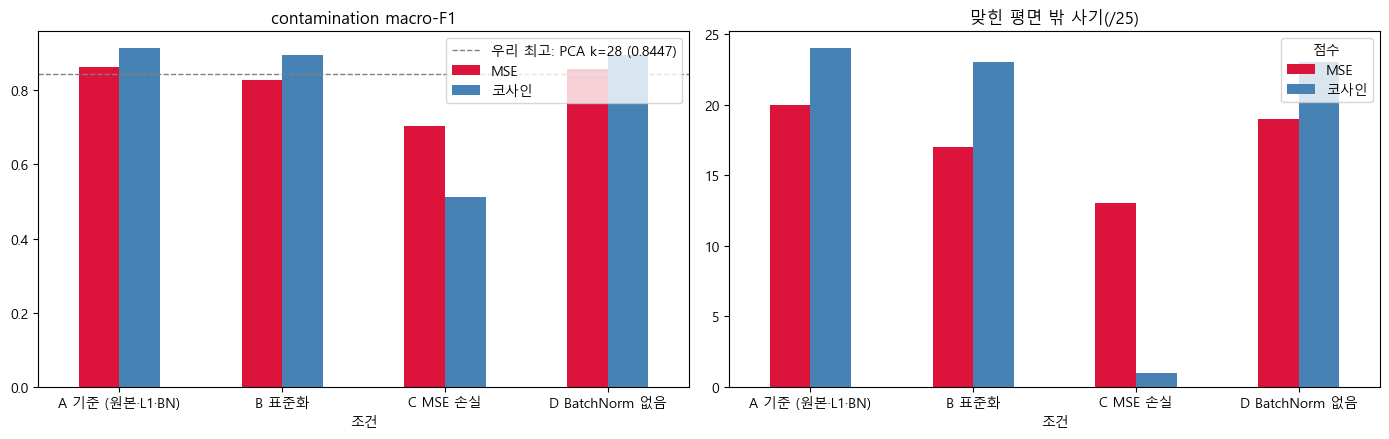

In [7]:
summary = pd.DataFrame(rows)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ['contamination macro-F1', '맞힌 평면 밖 사기(/25)']):
    pivot = summary.pivot(index='조건', columns='점수', values=col).loc[summary['조건'].unique()]
    pivot.plot(kind='bar', ax=ax, color=['crimson', 'steelblue'])
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=0)
axes[0].axhline(0.8447, color='gray', linestyle='--', linewidth=1, label='우리 최고: PCA k=28 (0.8447)')
axes[0].legend()
plt.tight_layout()
plt.show()

## 제출 파일: 조건 A + 코사인 점수 + contamination threshold

공유 코드(Public 0.926)는 val 정답으로 최고 에폭을 고르고 학습률을 조절했습니다. 조건 A는 **val 정답을 전혀 쓰지 않은** 버전이고,
threshold도 고정값 0.95 대신 지금까지 써온 contamination 방식(train 점수 상위 0.1055%)입니다.
val 정답 없이도 리더보드에서 원래 코드만큼 나오는지 확인합니다.

현재 우리 최고: PCA k=28 → Public 0.8658 / Private 0.8464

In [8]:
import os

model_A = models['A 기준 (원본·L1·BN)']
X_te_raw = test[v_cols].values.astype(np.float32)

s_tr_A = recon_scores(model_A, X_tr_raw)['코사인']
s_te_A = recon_scores(model_A, X_te_raw)['코사인']
threshold = np.quantile(s_tr_A, 1 - val_contamination)   # train 점수 기준 (val 정답은 안 봄)
pred_A = (s_te_A >= threshold).astype(int)

pd.DataFrame({'ID': test['ID'], 'Class': pred_A}).to_csv('../submissions/submission_phase4b_ae_l1_cosine.csv', index=False)
print(f'조건 A (L1 오토인코더 + 코사인): test 사기 예측 {pred_A.sum()}건 ({pred_A.mean() * 100:.3f}%)')
print('-> submissions/submission_phase4b_ae_l1_cosine.csv')

# 현재 최고 제출(PCA k=28)과 얼마나 겹치는지
pca_path = '../submissions/submission_phase4_pca_k28.csv'
if os.path.exists(pca_path):
    pred_pca = pd.read_csv(pca_path)['Class'].values
    print(f'PCA k=28: {pred_pca.sum()}건 / 둘 다 사기: {(pred_A & pred_pca).sum()}건, '
          f'오토인코더만: {(pred_A & (1 - pred_pca)).sum()}건, PCA만: {((1 - pred_A) & pred_pca).sum()}건')

조건 A (L1 오토인코더 + 코사인): test 사기 예측 291건 (0.204%)
-> submissions/submission_phase4b_ae_l1_cosine.csv
PCA k=28: 262건 / 둘 다 사기: 234건, 오토인코더만: 57건, PCA만: 28건
